In [10]:
# Step 0: Imports and Device Setup
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import Input, SimpleRNN, LSTM, Dense, TimeDistributed
from tensorflow.keras.callbacks import ReduceLROnPlateau, ModelCheckpoint

from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

In [2]:
# Load datasets
train_df = pd.read_csv('train_data.csv')
test_df = pd.read_csv('test_data.csv')

print(f"Train Shape: {train_df.shape} | Unique Engines: {train_df['engine_id'].nunique()}")
print(f"Test Shape:  {test_df.shape}  | Unique Engines: {test_df['engine_id'].nunique()}")

# Features list
features = [col for col in train_df.columns if col not in ['engine_id', 'RUL']]
print(f"Feature count ({len(features)}): {features}")

# Engine-level split to prevent cross-trajectory data leakage
unique_engines = train_df['engine_id'].unique()
np.random.seed(42)
train_engine_ids = np.random.choice(unique_engines, size=int(0.80 * len(unique_engines)), replace=False)
val_engine_ids = np.array([e for e in unique_engines if e not in train_engine_ids])

train_data = train_df[train_df['engine_id'].isin(train_engine_ids)].copy().reset_index(drop=True)
val_data = train_df[train_df['engine_id'].isin(val_engine_ids)].copy().reset_index(drop=True)

# Standardize features using training statistics only
scaler = StandardScaler()
train_data[features] = scaler.fit_transform(train_data[features])
val_data[features] = scaler.transform(val_data[features])

# Also scale test data for final inference
test_data = test_df.copy().reset_index(drop=True)
test_data[features] = scaler.transform(test_data[features])

print(f"Train rows: {len(train_data)} | Val rows: {len(val_data)}")


Train Shape: (61249, 27) | Unique Engines: 249
Test Shape:  (41214, 26)  | Unique Engines: 248
Feature count (25): ['cycle', 'op_setting_1', 'op_setting_2', 'op_setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']
Train rows: 48496 | Val rows: 12753


```markdown
## 1. Exploratory Data Analysis (EDA) & Data Cleaning
Let's visualize the distribution of maximum cycles (Engine Lifetimes) and some key operational sensor trends to understand the wear progression.
```

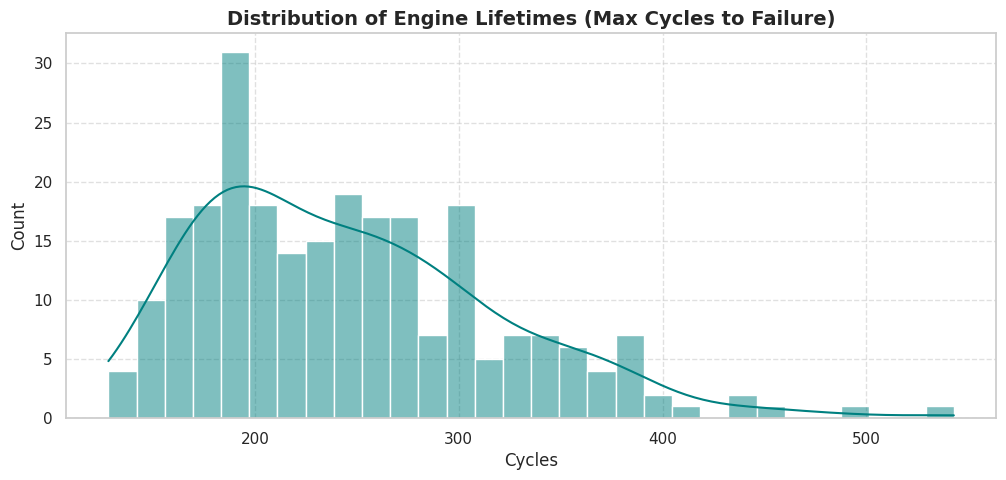

In [15]:
# Calculate maximum cycles per engine to check distribution of lifetimes
lifetimes = train_df.groupby('engine_id')['cycle'].max()

plt.figure(figsize=(12, 5))
sns.histplot(lifetimes, bins=30, kde=True, color='teal')
plt.title('Distribution of Engine Lifetimes (Max Cycles to Failure)', fontsize=14, fontweight='bold')
plt.xlabel('Cycles')
plt.ylabel('Count')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [3]:
X_train_ann = train_data[features]
y_train_ann = train_data['RUL']

X_val_ann = val_data[features]
y_val_ann = val_data['RUL']

ann_model = MLPRegressor(
    hidden_layer_sizes=(128, 64, 32),
    activation='relu',
    solver='adam',
    max_iter=100,
    random_state=42,
    early_stopping=True
)

print("Training Static ANN baseline...")
ann_model.fit(X_train_ann, y_train_ann)

y_val_ann_pred = ann_model.predict(X_val_ann)
ann_mae = mean_absolute_error(y_val_ann, y_val_ann_pred)
ann_rmse = np.sqrt(mean_squared_error(y_val_ann, y_val_ann_pred))
ann_r2 = r2_score(y_val_ann, y_val_ann_pred)

print(f"Static ANN Baseline -> MAE: {ann_mae:.2f} | RMSE: {ann_rmse:.2f} | R²: {ann_r2:.4f}")


Training Static ANN baseline...
Static ANN Baseline -> MAE: 36.97 | RMSE: 50.43 | R²: 0.7032


In [4]:
WINDOW_SIZE = 30

def create_seq2seq_windows(df, feature_cols, window_size=30):
    """Creates sliding windows for many-to-many regression per engine trajectory."""
    X_seqs = []
    y_seqs = []

    for engine_id, group in df.groupby('engine_id'):
        group_feat = group[feature_cols].values
        group_rul = group['RUL'].values

        num_cycles = len(group)
        if num_cycles < window_size:
            continue

        for i in range(num_cycles - window_size + 1):
            X_window = group_feat[i : i + window_size]
            y_window = group_rul[i : i + window_size]

            X_seqs.append(X_window)
            y_seqs.append(y_window)

    return np.array(X_seqs, dtype=np.float32), np.array(y_seqs, dtype=np.float32)[..., np.newaxis]

print("Generating sliding windows...")
X_train_seq, y_train_seq = create_seq2seq_windows(train_data, features, WINDOW_SIZE)
X_val_seq, y_val_seq = create_seq2seq_windows(val_data, features, WINDOW_SIZE)

print(f"Train sequences: X = {X_train_seq.shape}, y = {y_train_seq.shape}")
print(f"Val sequences:   X = {X_val_seq.shape}, y = {y_val_seq.shape}")

Generating sliding windows...
Train sequences: X = (42725, 30, 25), y = (42725, 30, 1)
Val sequences:   X = (11303, 30, 25), y = (11303, 30, 1)


In [5]:
def build_seq2seq_rnn(input_shape=(30, 25), hidden_dim=64):
    # Many-to-Many RNN architecture
    inputs = Input(shape=input_shape)
    x = SimpleRNN(hidden_dim, return_sequences=True, dropout=0.2)(inputs)
    # Second RNN layer to match PyTorch's num_layers=2
    x = SimpleRNN(hidden_dim, return_sequences=True, dropout=0.2)(x)

    # Dense projection per time step (TimeDistributed)
    x = TimeDistributed(Dense(32, activation='relu'))(x)
    outputs = TimeDistributed(Dense(1))(x)

    model = Model(inputs=inputs, outputs=outputs, name="Seq2Seq_SimpleRNN")
    return model

def build_seq2seq_lstm(input_shape=(30, 25), hidden_dim=64):
    # Many-to-Many LSTM architecture
    inputs = Input(shape=input_shape)
    x = LSTM(hidden_dim, return_sequences=True, dropout=0.2)(inputs)
    # Second LSTM layer to match PyTorch's num_layers=2
    x = LSTM(hidden_dim, return_sequences=True, dropout=0.2)(x)

    # Dense projection per time step (TimeDistributed)
    x = TimeDistributed(Dense(32, activation='relu'))(x)
    outputs = TimeDistributed(Dense(1))(x)

    model = Model(inputs=inputs, outputs=outputs, name="Seq2Seq_LSTM")
    return model

In [6]:
def train_keras_model(model, X_train, y_train, X_val, y_val, model_path, epochs=25, batch_size=128):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='mse'
    )

    callbacks = [
        ReduceLROnPlateau(monitor='val_loss', mode='min', factor=0.5, patience=3, verbose=1),
        ModelCheckpoint(model_path, monitor='val_loss', mode='min', save_best_only=True, verbose=1)
    ]

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=callbacks,
        verbose=1
    )

    # Load the best saved model weights for inference evaluation
    best_model = load_model(model_path)
    return best_model, history

print("--- Training Seq2Seq SimpleRNN ---")
rnn_raw = build_seq2seq_rnn(input_shape=(WINDOW_SIZE, len(features)), hidden_dim=64)
rnn_model, rnn_history = train_keras_model(
    rnn_raw, X_train_seq, y_train_seq, X_val_seq, y_val_seq,
    model_path='seq2seq_rnn_best.keras', epochs=25, batch_size=128
)

print("\n--- Training Seq2Seq LSTM ---")
lstm_raw = build_seq2seq_lstm(input_shape=(WINDOW_SIZE, len(features)), hidden_dim=64)
lstm_model, lstm_history = train_keras_model(
    lstm_raw, X_train_seq, y_train_seq, X_val_seq, y_val_seq,
    model_path='seq2seq_lstm_best.keras', epochs=25, batch_size=128
)

--- Training Seq2Seq SimpleRNN ---
Epoch 1/25
334/334 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 17209.1080
Epoch 1: val_loss improved from None to 7533.56445, saving model to seq2seq_rnn_best.keras

Epoch 1: finished saving model to seq2seq_rnn_best.keras
334/334 ━━━━━━━━━━━━━━━━━━━━ 36s 62ms/step - loss: 11932.2266 - val_loss: 7533.5645 - learning_rate: 0.0010
Epoch 2/25
331/334 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 6819.2573
Epoch 2: val_loss improved from 7533.56445 to 6880.72754, saving model to seq2seq_rnn_best.keras

Epoch 2: finished saving model to seq2seq_rnn_best.keras
334/334 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 6923.0781 - val_loss: 6880.7275 - learning_rate: 0.0010
Epoch 3/25
331/334 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 5542.9378
Epoch 3: val_loss improved from 6880.72754 to 4838.63770, saving model to seq2seq_rnn_best.keras

Epoch 3: finished saving model to seq2seq_rnn_best.keras
334/334 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 5284.6704 - val_loss: 4838.6377 

In [7]:
def evaluate_seq_predictions(model, X_seq, y_seq):
    # Predictions shape: (N, W, 1)
    all_preds = model.predict(X_seq, batch_size=256)
    all_targets = y_seq

    # Flatten across all time steps
    preds_all = all_preds.reshape(-1)
    targets_all = all_targets.reshape(-1)

    mae_all = mean_absolute_error(targets_all, preds_all)
    rmse_all = np.sqrt(mean_squared_error(targets_all, preds_all))
    r2_all = r2_score(targets_all, preds_all)

    # Final step only (the W-th cycle)
    preds_final = all_preds[:, -1, 0]
    targets_final = all_targets[:, -1, 0]

    mae_final = mean_absolute_error(targets_final, preds_final)
    rmse_final = np.sqrt(mean_squared_error(targets_final, preds_final))
    r2_final = r2_score(targets_final, preds_final)

    return {
        'all': {'mae': mae_all, 'rmse': rmse_all, 'r2': r2_all, 'preds': preds_all, 'targets': targets_all},
        'final': {'mae': mae_final, 'rmse': rmse_final, 'r2': r2_final, 'preds': preds_final, 'targets': targets_final}
    }

rnn_eval = evaluate_seq_predictions(rnn_model, X_val_seq, y_val_seq)
lstm_eval = evaluate_seq_predictions(lstm_model, X_val_seq, y_val_seq)

# Construct Comparison DataFrame
comparison_df = pd.DataFrame([
    {
        "Model": "Static Snapshot ANN Baseline",
        "Evaluation Scope": "Snapshot (Single Step)",
        "MAE (Cycles)": round(ann_mae, 2),
        "RMSE (Cycles)": round(ann_rmse, 2),
        "R² Score": round(ann_r2, 4)
    },
    {
        "Model": "Seq2Seq SimpleRNN",
        "Evaluation Scope": "All Time Steps (N x 30)",
        "MAE (Cycles)": round(rnn_eval['all']['mae'], 2),
        "RMSE (Cycles)": round(rnn_eval['all']['rmse'], 2),
        "R² Score": round(rnn_eval['all']['r2'], 4)
    },
    {
        "Model": "Seq2Seq SimpleRNN",
        "Evaluation Scope": "Final Step Only (Fair vs. ANN)",
        "MAE (Cycles)": round(rnn_eval['final']['mae'], 2),
        "RMSE (Cycles)": round(rnn_eval['final']['rmse'], 2),
        "R² Score": round(rnn_eval['final']['r2'], 4)
    },
    {
        "Model": "Seq2Seq LSTM",
        "Evaluation Scope": "All Time Steps (N x 30)",
        "MAE (Cycles)": round(lstm_eval['all']['mae'], 2),
        "RMSE (Cycles)": round(lstm_eval['all']['rmse'], 2),
        "R² Score": round(lstm_eval['all']['r2'], 4)
    },
    {
        "Model": "Seq2Seq LSTM",
        "Evaluation Scope": "Final Step Only (Fair vs. ANN)",
        "MAE (Cycles)": round(lstm_eval['final']['mae'], 2),
        "RMSE (Cycles)": round(lstm_eval['final']['rmse'], 2),
        "R² Score": round(lstm_eval['final']['r2'], 4)
    }
])

display(comparison_df)

45/45 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step


,Model,Evaluation Scope,MAE (Cycles),RMSE (Cycles),R² Score
0,Static Snapshot ANN Baseline,Snapshot (Single Step),36.97,50.43,0.7032
1,Seq2Seq SimpleRNN,All Time Steps (N x 30),44.13,58.65,0.5404
2,Seq2Seq SimpleRNN,Final Step Only (Fair vs. ANN),40.04,54.25,0.6028
3,Seq2Seq LSTM,All Time Steps (N x 30),42.58,57.81,0.5536
4,Seq2Seq LSTM,Final Step Only (Fair vs. ANN),38.31,53.37,0.6155


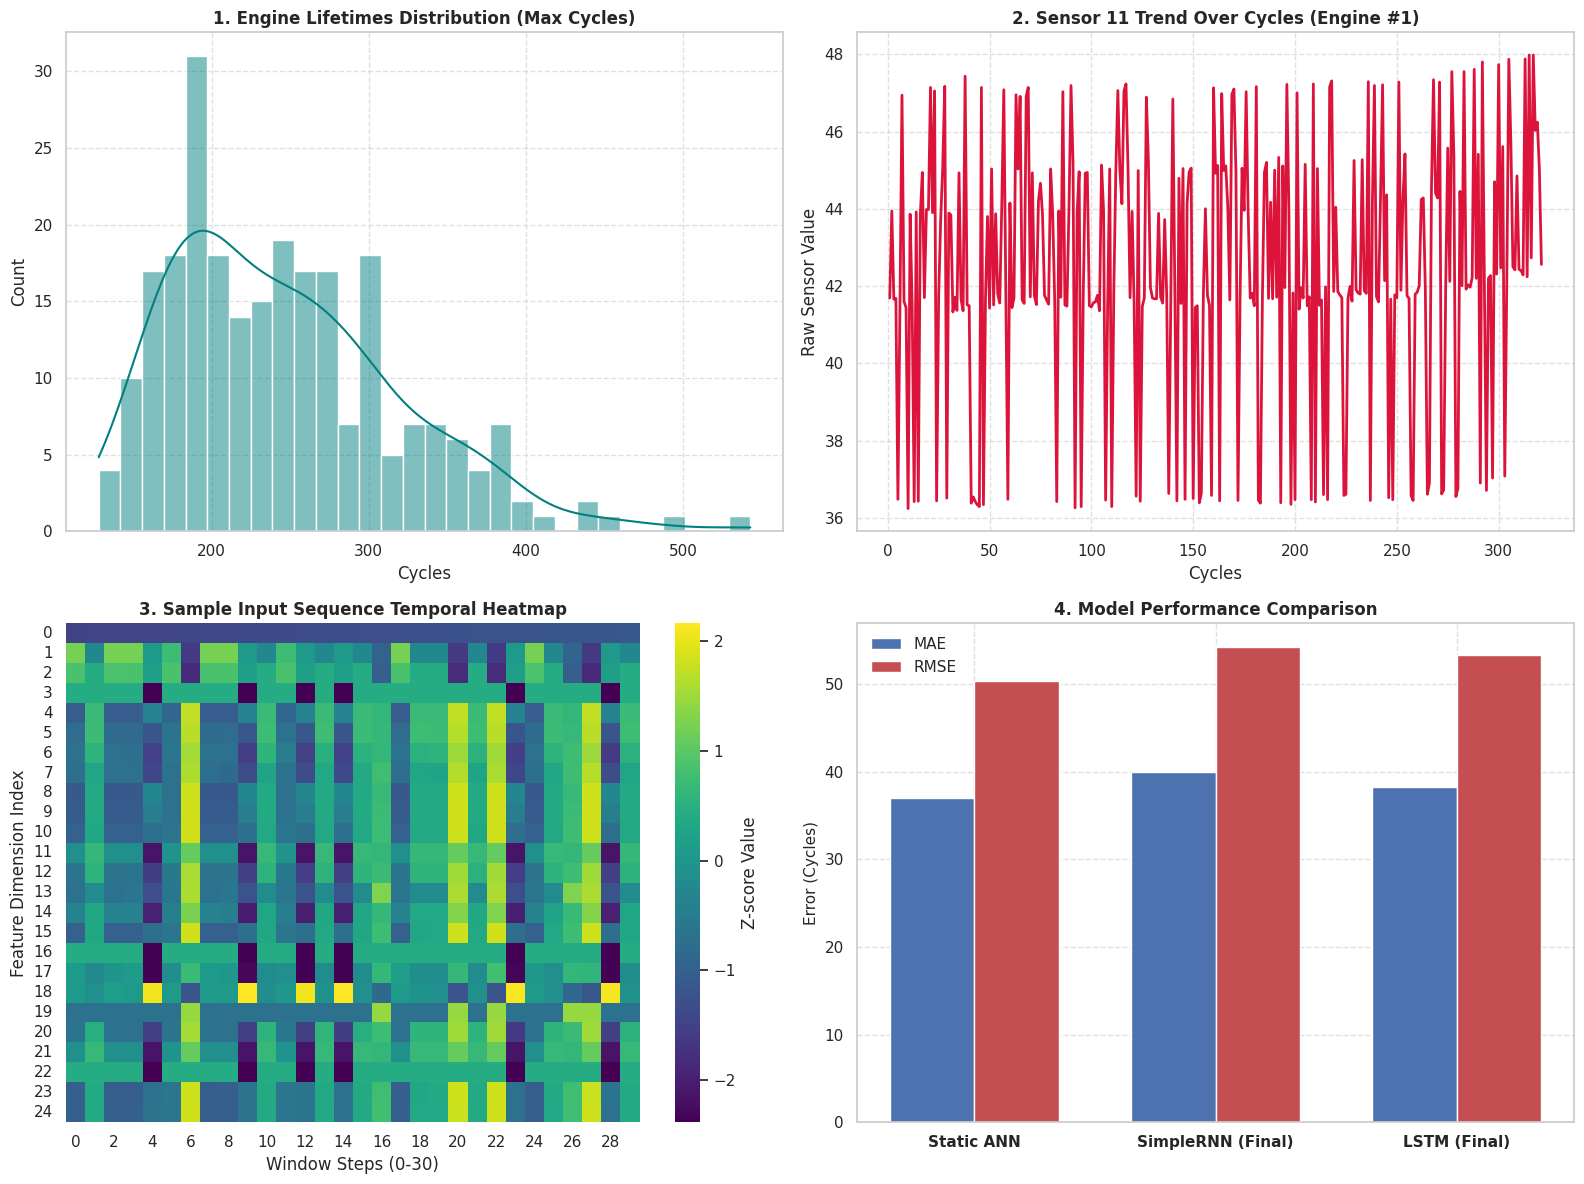

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Data Distribution (Engine Lifetimes)
lifetimes = train_df.groupby('engine_id')['cycle'].max()
sns.histplot(lifetimes, bins=30, kde=True, color='teal', ax=axes[0, 0])
axes[0, 0].set_title('1. Engine Lifetimes Distribution (Max Cycles)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Cycles')
axes[0, 0].set_ylabel('Count')
axes[0, 0].grid(True, linestyle='--', alpha=0.6)

# 2. Sensor Trends (Degradation Trend over Operational Cycles)
single_engine_raw = train_df[train_df['engine_id'] == 1]
sns.lineplot(x='cycle', y='sensor_11', data=single_engine_raw, ax=axes[0, 1], color='crimson', lw=2)
axes[0, 1].set_title('2. Sensor 11 Trend Over Cycles (Engine #1)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Cycles')
axes[0, 1].set_ylabel('Raw Sensor Value')
axes[0, 1].grid(True, linestyle='--', alpha=0.6)

# 3. Sample Window Input Temporal Heatmap (Sample Images)
sample_window = X_train_seq[0]
sns.heatmap(sample_window.T, cmap='viridis', cbar_kws={'label': 'Z-score Value'}, ax=axes[1, 0])
axes[1, 0].set_title('3. Sample Input Sequence Temporal Heatmap', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Feature Dimension Index')
axes[1, 0].set_xlabel('Window Steps (0-30)')

# 4. Model Performance Comparisons
models_list = ['Static ANN', 'SimpleRNN (Final)', 'LSTM (Final)']
mae_values = [ann_mae, rnn_eval['final']['mae'], lstm_eval['final']['mae']]
rmse_values = [ann_rmse, rnn_eval['final']['rmse'], lstm_eval['final']['rmse']]

x_indices = np.arange(len(models_list))
bar_width = 0.35

axes[1, 1].bar(x_indices - bar_width/2, mae_values, bar_width, label='MAE', color='#4c72b0')
axes[1, 1].bar(x_indices + bar_width/2, rmse_values, bar_width, label='RMSE', color='#c44e52')
axes[1, 1].set_xticks(x_indices)
axes[1, 1].set_xticklabels(models_list, fontweight='bold')
axes[1, 1].set_ylabel('Error (Cycles)', fontsize=11)
axes[1, 1].set_title('4. Model Performance Comparison', fontsize=12, fontweight='bold')
axes[1, 1].legend()
axes[1, 1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [11]:
rnn_model.save('seq2seq_rnn_model.keras')
lstm_model.save('seq2seq_lstm_model.keras')
joblib.dump(ann_model, 'static_ann_model.pkl')
joblib.dump(scaler, 'seq2seq_scaler.pkl')

print("All Keras sequence models, Static ANN baseline, and scalers saved successfully!")

All Keras sequence models, Static ANN baseline, and scalers saved successfully!
